# Q1 - Copy Mutate Algorithm
Group No: ____

In this notebook we implement the copy mutate algorithm on the dataset we got from Assignment 1 (`ner_ingredient_pairs.csv`).

Idea in short:
- start with a small number of random recipes (primordial cuisine)
- keep copying a recipe and changing one of its ingredients (mutation)
- keep adding the new recipes until we get the same number of recipes as the real data
- do this in epochs and for 5 different runs, then plot the results

In [36]:
import os
import random
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Step 1: Parameters
We can change all the values from here. All plots are saved in the `Q1_output` folder, which is in the same folder as this notebook.
- `N_EPOCHS` = number of epochs
- `NR0` = number of recipes at the start (t = 0)
- `KB_RATIO` = size of kitchen basket / size of nature basket
- `N_RUNS` = how many times we run the whole evolution

In [37]:
DATA_PATH = "ner_ingredient_pairs.csv"
N_EPOCHS = 10
NR0 = 300
KB_RATIO = 0.02
N_RUNS = 5
SEED = 42
OUTPUT_DIR = "Q1_output"     # folder for the plots (same folder as Q1.ipynb)

## Step 2: Load the data
Each row of the csv has a recipe id and one ingredient. So we group by recipe id and make a set of ingredients for each recipe (set because we don't want repeated ingredients in a recipe).

From this we get:
- total number of recipes
- nature basket (NB) = all unique ingredients
- recipe size `s` = average number of ingredients in a recipe (rounded)

In [38]:
os.makedirs(OUTPUT_DIR, exist_ok=True)     # make output folder if it is not there

if not os.path.exists(DATA_PATH):
    DATA_PATH = "/mnt/user-data/uploads/ner_ingredient_pairs.csv"

df = pd.read_csv(DATA_PATH)
df["ingredient"] = df["extracted_ingredient_name"].astype(str).str.strip().str.lower()

real_recipes = df.groupby("recipe_id")["ingredient"].apply(set)
real_sizes = real_recipes.apply(len)

N_RECIPES = len(real_recipes)
NATURE_BASKET = sorted(df["ingredient"].unique())
NB_SIZE = len(NATURE_BASKET)
s = int(round(real_sizes.mean()))

print("Number of recipes:", N_RECIPES)
print("Size of nature basket:", NB_SIZE)
print("Average recipe size:", round(real_sizes.mean(), 2))
print("Recipe size s used:", s)

Number of recipes: 7538
Size of nature basket: 5893
Average recipe size: 13.07
Recipe size s used: 13


## Step 3: Epochs and recipes per epoch
recipes per epoch = round(total recipes / number of epochs)

At the end of epoch k the cuisine should have `k * recipes_per_epoch` recipes. For the last epoch we just use the total number of recipes.

Kitchen basket size = KB_RATIO x nature basket size (it should be more than `s`, otherwise we cannot make unique recipes).

In [39]:
RECIPES_PER_EPOCH = round(N_RECIPES / N_EPOCHS)

epoch_targets = []
for k in range(1, N_EPOCHS + 1):
    epoch_targets.append(min(k * RECIPES_PER_EPOCH, N_RECIPES))

KB_SIZE = max(round(KB_RATIO * NB_SIZE), s + 1)

print("Recipes per epoch:", RECIPES_PER_EPOCH)
print("Target recipes at end of each epoch:", epoch_targets)
print("Kitchen basket size:", KB_SIZE)

Recipes per epoch: 754
Target recipes at end of each epoch: [754, 1508, 2262, 3016, 3770, 4524, 5278, 6032, 6786, 7538]
Kitchen basket size: 118


## Step 4: Primordial cuisine (epoch 0)
- pick `KB_SIZE` random ingredients from the nature basket -> this is the kitchen basket
- make `NR0` random recipes of size `s` from the kitchen basket
- all recipes should be unique, so we check with a set

In [40]:
def make_primordial(rng):
    kb = rng.sample(NATURE_BASKET, KB_SIZE)
    recipes = []
    seen = set()
    while len(recipes) < NR0:
        r = rng.sample(kb, s)
        key = frozenset(r)
        if key not in seen:
            seen.add(key)
            recipes.append(r)
    return kb, recipes, seen

## Step 5: Copy mutate algorithm
For one new recipe:
1. pick a random recipe and copy it
2. pick a random ingredient from the recipe and a random ingredient from the kitchen basket
3. if they are different, replace the recipe ingredient with the kitchen basket one (we also make sure the new ingredient is not already in the recipe, else the recipe size will reduce)
4. if they are same, pick again (repeat until recipe is modified)
5. add the new recipe to the cuisine only if it is not already there
6. repeat till we reach the target of that epoch

In [41]:
def mutate(parent, kb, rng):
    child = list(parent)          # copy of the recipe
    while True:
        pos = rng.randrange(len(child))
        new_ing = rng.choice(kb)
        if new_ing != child[pos] and new_ing not in child:
            child[pos] = new_ing
            return child

In [42]:
def get_stats(recipes, counts):
    # recipe size distribution and normalised frequency (sorted high to low)
    n = len(recipes)
    size_count = Counter(len(r) for r in recipes)
    freq = sorted(counts.values(), reverse=True)
    freq = np.array(freq) / n
    return {"n": n, "size_count": size_count, "freq": freq}


def run_cuisine(seed):
    rng = random.Random(seed)
    kb, recipes, seen = make_primordial(rng)
    counts = Counter()                      # in how many recipes each ingredient is present
    for r in recipes:
        counts.update(r)

    all_epochs = []
    for target in epoch_targets:
        while len(recipes) < target:
            parent = rng.choice(recipes)
            child = mutate(parent, kb, rng)
            key = frozenset(child)
            if key in seen:                 # recipe already there, skip it
                continue
            seen.add(key)
            recipes.append(child)
            counts.update(child)
        all_epochs.append(get_stats(recipes, counts))   # save stats at end of epoch
    return all_epochs

## Step 6: One run - plots for each epoch
We run the algorithm once and plot recipe size distribution and normalised frequency-rank distribution for every epoch.

In [43]:
run0 = run_cuisine(SEED)
print("recipes in final cuisine:", run0[-1]["n"])
print("ingredients used in final cuisine:", len(run0[-1]["freq"]))

recipes in final cuisine: 7538
ingredients used in final cuisine: 118


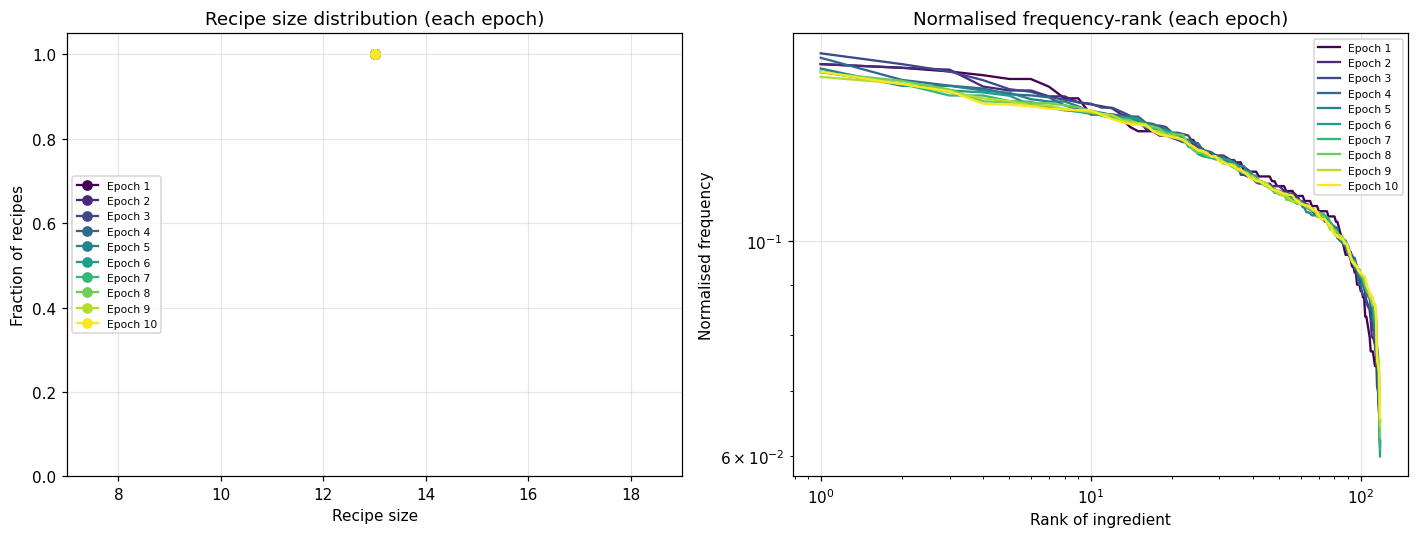

In [44]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
colors = plt.cm.viridis(np.linspace(0, 1, N_EPOCHS))

for i in range(N_EPOCHS):
    st = run0[i]
    sizes = sorted(st["size_count"])
    frac = [st["size_count"][x] / st["n"] for x in sizes]
    ax1.plot(sizes, frac, "o-", color=colors[i], label="Epoch " + str(i + 1))

    ranks = np.arange(1, len(st["freq"]) + 1)
    ax2.loglog(ranks, st["freq"], color=colors[i], label="Epoch " + str(i + 1))

ax1.set_xlim(s - 6, s + 6)
ax1.set_ylim(0, 1.05)
ax1.set_xlabel("Recipe size")
ax1.set_ylabel("Fraction of recipes")
ax1.set_title("Recipe size distribution (each epoch)")
ax1.legend(fontsize=7, loc="center left")

ax2.set_xlabel("Rank of ingredient")
ax2.set_ylabel("Normalised frequency")
ax2.set_title("Normalised frequency-rank (each epoch)")
ax2.legend(fontsize=7)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "Q1_Fig1_RecipeSize_FreqRank_per_Epoch.png"), dpi=200)
plt.show()

## Step 7: Run 5 instances
Now we run the whole evolution 5 times with different random seeds. We take the final epoch of each run for the next plots.

In [45]:
runs = []
for r in range(N_RUNS):
    runs.append(run_cuisine(SEED + r))
    print("run", r + 1, "done")

final = [run[-1] for run in runs]

run 1 done
run 2 done
run 3 done
run 4 done
run 5 done


## Step 8: Recipe size distribution (mean and std)
We find the fraction of recipes of each size in every run, then take mean and standard deviation over the runs. The grey bars are the real data.

Note: in this question all recipes have the same size `s`, so we only get one point and std is almost 0. In Q2 (addition/deletion) the sizes will change.

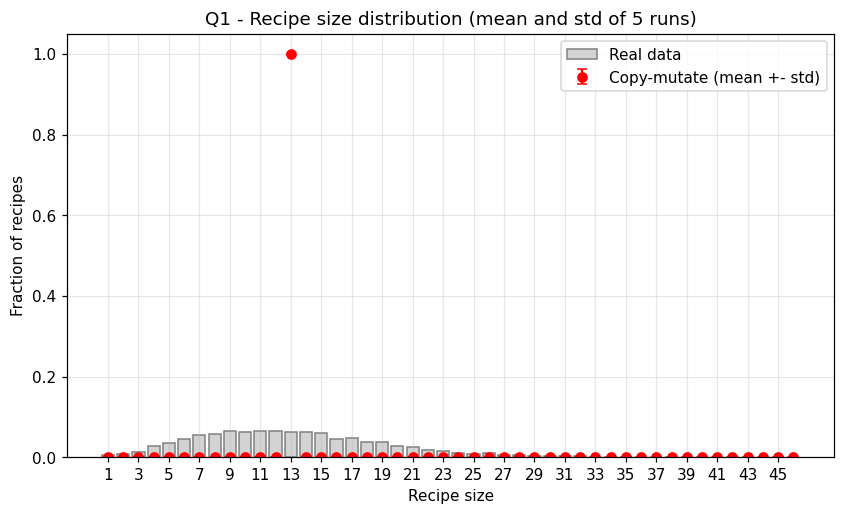

In [46]:
max_size = int(max(real_sizes.max(), s)) + 1
sizes = np.arange(1, max_size + 1)

all_frac = []
for f in final:
    row = [f["size_count"].get(x, 0) / f["n"] for x in sizes]
    all_frac.append(row)
all_frac = np.array(all_frac)

mean_size = all_frac.mean(axis=0)
std_size = all_frac.std(axis=0)

real_frac = [(real_sizes == x).mean() for x in sizes]

plt.figure(figsize=(9, 5))
plt.bar(sizes, real_frac, color="lightgrey", edgecolor="grey", label="Real data")
plt.errorbar(sizes, mean_size, yerr=std_size, fmt="o", color="red", capsize=3, label="Copy-mutate (mean +- std)")
plt.xticks(sizes[::2])
plt.xlabel("Recipe size")
plt.ylabel("Fraction of recipes")
plt.title("Q1 - Recipe size distribution (mean and std of 5 runs)")
plt.legend()
plt.savefig(os.path.join(OUTPUT_DIR, "Q1_Fig2_RecipeSizeDistribution_MeanSD.png"), dpi=200)
plt.show()

## Step 9: Normalised frequency-rank distribution
Normalised frequency = (number of recipes having the ingredient) / (total recipes).
We sort it from highest to lowest and plot against rank on log-log scale. The line is the mean of 5 runs and the shaded part is mean +- std. Grey line is the real data.

The simulated line stops early because only the ingredients of the kitchen basket can come in the recipes.

The std is very small (about 1-2% of the mean), so in the full plot the shaded part is hardly visible. That is why we also plot a zoomed view on the right where the std can be seen.

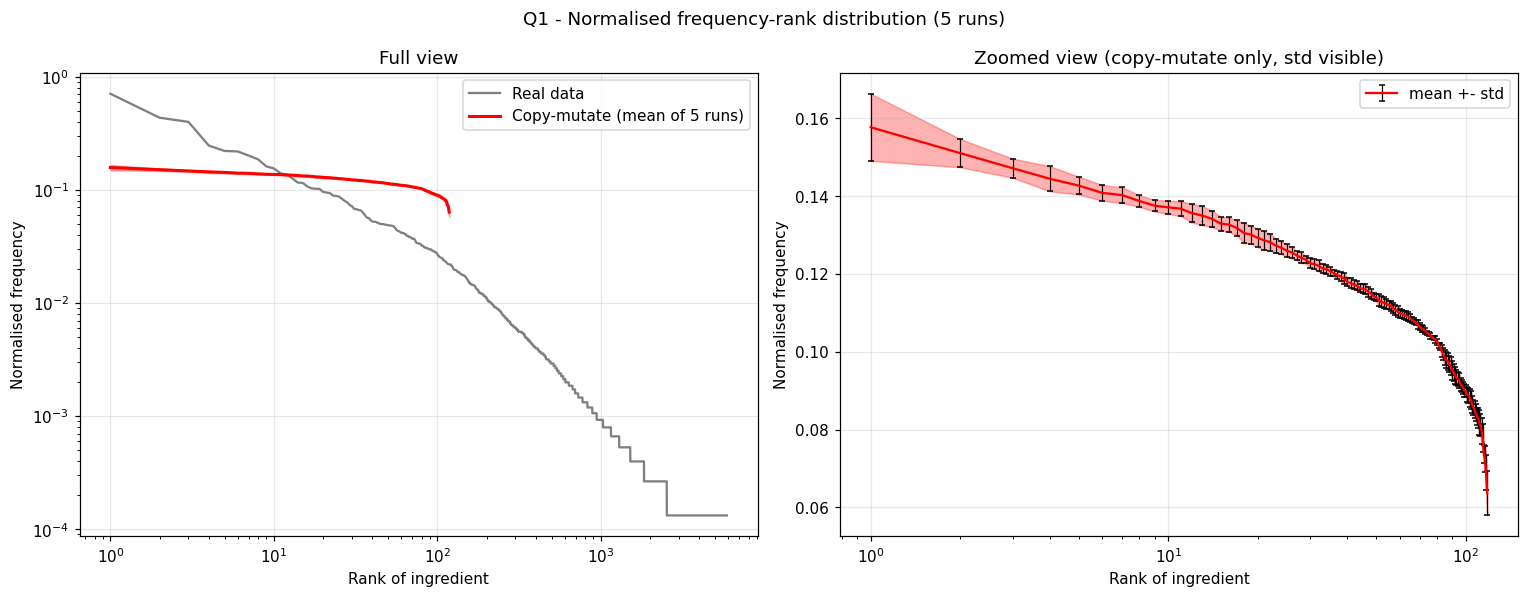

In [47]:
L = min(len(f["freq"]) for f in final)          # use same number of ranks for all runs
F = np.array([f["freq"][:L] for f in final])
mean_f = F.mean(axis=0)
std_f = F.std(axis=0)
ranks = np.arange(1, L + 1)

# real data
real_counts = df.drop_duplicates(["recipe_id", "ingredient"])["ingredient"].value_counts()
real_freq = real_counts.values / N_RECIPES

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

# left: full plot with real data
ax1.loglog(np.arange(1, len(real_freq) + 1), real_freq, color="grey", label="Real data")
ax1.loglog(ranks, mean_f, color="red", linewidth=2, label="Copy-mutate (mean of 5 runs)")
ax1.fill_between(ranks, np.clip(mean_f - std_f, 1e-6, None), mean_f + std_f, color="red", alpha=0.3)
ax1.set_xlabel("Rank of ingredient")
ax1.set_ylabel("Normalised frequency")
ax1.set_title("Full view")
ax1.legend()

# right: zoom on simulated part only, so that std can be seen
ax2.errorbar(ranks, mean_f, yerr=std_f, fmt="-", color="red", ecolor="black", elinewidth=0.8, capsize=2, label="mean +- std")
ax2.fill_between(ranks, mean_f - std_f, mean_f + std_f, color="red", alpha=0.3)
ax2.set_xscale("log")
ax2.set_xlabel("Rank of ingredient")
ax2.set_ylabel("Normalised frequency")
ax2.set_title("Zoomed view (copy-mutate only, std visible)")
ax2.legend()

plt.suptitle("Q1 - Normalised frequency-rank distribution (5 runs)")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "Q1_Fig3_NormalisedFreqRank.png"), dpi=200)
plt.show()

## Conclusion
- The algorithm was run for 10 epochs and 5 runs and the cuisine grew to the same number of recipes as the real data.
- Recipe size stays fixed at `s` because we only modify ingredients.
- The frequency-rank curve is flat compared to the real data because every kitchen basket ingredient has the same chance of being picked. We will try to fix this in Q3.

Saved plots (in the `Q1_output` folder): `Q1_Fig1_RecipeSize_FreqRank_per_Epoch.png`, `Q1_Fig2_RecipeSizeDistribution_MeanSD.png`, `Q1_Fig3_NormalisedFreqRank.png`